# PartNet · 正式实验

按 **Cell 1 → Cell 11** 顺序运行，或使用 **Restart Kernel and Run All**。本 notebook 不再执行 calibration、description QA、matcher 自检或旧 decomposition pilot。

**已冻结、只读的输入**（放在 `project_dir`）：
- `partnet_benchmark_manifest.json`
- `partnet_descriptions_880.json`（含每个对象的 `source.parts`）
- `partnet_physical_adjacency_880.json`

已完成的 `partnet_shared_part_specs_880_final.json` / `..._final_checkpoint.json` 会自动导入；没有时仅生成缺失的 shared connections。不会读取旧的非 final development specs，不会覆盖任何上述原始 JSON。

**依赖**：`numpy scipy pandas matplotlib openai`；Jupyter 环境需要支持 Python 3.10+。将本 notebook 与本次整理的 `methods.py` 放在同一目录。API key 使用环境变量 `DEEPSEEK_API_KEY`；未设置时只在首次真正需要调用 API 时隐藏输入。

**执行范围**：当前 PartNet 三表示静态比较、Random Anchor、多 seed object-level 汇总、all-shared-edge part-scale perturbation、配对统计和定性布局。PartNet-Mobility、自然语言编辑、GT rotation 和 mesh contact-region attachment-location 尚未实现，不在本 notebook 中伪装成已完成实验。

## Cell 1 — 导入

In [97]:
import os
import importlib
import methods
from IPython.display import display
importlib.reload(methods)
from methods import *

## Cell 2 — 唯一配置入口
默认沿用你现有 notebook 的 `deepseek-chat` / `temperature=0.0`，三种表示使用相同配置，不自动换模型。
`workers=4` 仅并发不同对象；每个对象内部的重试顺序固定。`allow_api=True` 会在 Cell 5 / 6 对未完成条目产生实际 API 调用及费用。

同一 `output_dir` 不允许混用不同输入、prompt 或模型配置。已有结果全部复用；切换模型做新实验时使用新目录。只重算指标时设置 `allow_api=False`，也可以直接重跑 Cell 7–11（当前 kernel 已有变量时）。

In [98]:
cfg = PartNetConfig()
cfg.partnet_root = r"E:\datasets\partnet"
cfg.project_dir = "."
cfg.output_dir = r"partnet_results\experiments2"
cfg.model = os.getenv("DEEPSEEK_MODEL", "deepseek-chat")
cfg.temperature = 0.0
cfg.max_tokens = 8192
cfg.max_attempts = 3
cfg.workers = 4
cfg.allow_api = False
cfg.object_limit = None
cfg.random_anchor_seeds = (0, 1, 2, 3, 4)
cfg.scale_factors = (0.8, 1.2, 1.5)
cfg.bootstrap_samples = 10000

## Cell 3 — 读取冻结输入
只做 ID、数量与文件一致性的必要检查，不再次生成描述或邻接图。

In [85]:
inputs = load_partnet_inputs(cfg)

冻结输入: 880 objects；描述/邻接图只读，不调用 LLM。


## Cell 4 — GT 几何缓存
从最新版 parser 读取 exclusive referenced geometry，保持 `[-x,z,y]` canonical conversion 与 object-level normalization。首次缓存 GT 中心/尺寸；后续直接读缓存。不计算任何 mesh pair distance。

In [86]:
gt_cache = prepare_partnet_gt_cache(inputs, cfg)

GT cache: 100/880
GT cache: 200/880
GT cache: 300/880
GT cache: 400/880
GT cache: 500/880
GT cache: 600/880
GT cache: 700/880
GT cache: 800/880
GT cache: 880/880


## Cell 5 — 复用/补全共享结构
固定 inventory，LLM 只生成 root + connections。优先复用已存在的 connection-only final JSON。
最多三次 schema-validity attempts，原始回复、错误和已用次数持久保存；重复运行不会重置失败预算。耗尽预算的对象留在失败统计中，不人工补树。

In [87]:
shared_specs = run_partnet_shared_specs(inputs, cfg)

Shared specs: valid=877/880；历史结果复用，失败不补造树。


## Cell 6 — 三分支 generation
同一个 description、parts、connections；只变 representation system prompt。
Global / Local / Anchor 独立生成。LLM 仅输出固定 part_id 的几何参数，部件名字与连接由共享 spec 赋回，避免重复生成 hierarchy 导致 branch 偏离。

Anchor offset 明确定义在 **parent local frame**；Local 非 root 必须提供 relative_position 和 relative_rotation；Global 每个 part 使用 absolute center/rotation。共享 root 本身有 geometry，不被丢弃。

In [90]:
generation = run_partnet_generation(shared_specs, cfg)

anchor: valid=877/880
global: valid=877/880
local: 20/155
local: 40/155
local: 60/155
local: 80/155
local: 100/155
local: 120/155
local: 140/155
local: 155/155
local: valid=877/880


## Cell 7 — 离线静态 evaluation
预测整体按实际旋转 bbox union 居中，最长 extent=1。严格 semantic group 内 Hungarian matching；不跨名字 fuzzy matching。

新 PartNet 指标：canonical relative translation、world-AABB size MAE、GT-edge bbox margin discrepancy、OBB SAT gap/contact proxy、shared-edge gap/penetration deviation、OBB overlap pair fraction、part volume。尺寸误差不除以近零 GT dimension。

**边界**：GT reference 是 mesh-derived adjacency，预测只有 OBB；SAT 指标是明确标注的 box proxy，不称作 exact mesh attachment error。无 GT rotation / contact-location 总分。相同语义描述可能对应多种 GT 形状，因此 pose error 仅衡量与该 GT instance 的一致性。

In [91]:
evaluation = run_partnet_evaluation(inputs, shared_specs, generation, gt_cache, cfg)

静态评估: 2631 method-object records；三方法共同有效样本 877/880；evaluation failures=0


## Cell 8 — Random Anchor（无 LLM 调用）
仅替换 Anchor 原始 JSON 的 parent/child anchors；bbox、rotation、offset 和 shared tree 不变。
每个对象 5 seeds 后先取 object-level average。**沿用原 Anchor 的 normalization 和匹配**，不让重新缩放或重新匹配掩盖布局破坏。

In [92]:
random_anchor = run_partnet_random_anchor(inputs, shared_specs, generation, evaluation, gt_cache, cfg)

Random Anchor: 877 objects × 5 seeds；未调用 LLM。


## Cell 9 — All-edge scale perturbation（无 LLM 调用）
依次对每条 shared connection 的 child bbox 单独做 0.8 / 1.2 / 1.5 缩放；每次从原始 JSON 开始。
固定扰动前 normalization；记录目标 edge 的原始/扰动后 SAT deviation 与 margin drift，再对 object 内所有 interventions 求均值。不在 transform 后的内存 tree 上累计修改。

In [93]:
perturbation = run_partnet_scale_perturbation(inputs, shared_specs, generation, evaluation, cfg)

All-edge scale perturbation: 7893 method-object-scale records；未调用 LLM。


## Cell 10 — 主表、消融和统计输出
主比较使用三方法共同有效的 object IDs；所有失败和 all-available 汇总另存，不静默丢样本。
统计单位始终是 object：category-stratified bootstrap CI、paired Wilcoxon、win/tie/loss、Holm correction。`part_volume_sum` 仅描述，不设为默认主检验目标。

In [94]:
tables = export_partnet_results(inputs, shared_specs, generation, evaluation, random_anchor, perturbation, cfg)
display(partnet_summary_view(tables, "summary"))
display(partnet_summary_view(tables, "perturbation_summary"))
statistics = partnet_summary_view(tables, "paired_statistics")
display(statistics)
print("输出目录:", cfg.output_path())

已导出 tables/*.csv；主表共同有效样本 877/880。失败样本见 generation_status.csv。


metric,center_error,gt_edge_bbox_contact_rate,gt_edge_bbox_margin_mae,gt_edge_obb_sat_gap,obb_overlap_pair_fraction,part_volume_sum,relative_translation_error,shared_edge_obb_sat_deviation,shared_edge_obb_sat_gap,world_aabb_size_mae
method,,,,,,,,,,
anchor,0.256004,0.769738,0.106823,0.056020,0.139380,0.119157,0.353095,0.027839,0.000424,0.173197
global,0.238642,0.757751,0.127244,0.059560,0.238131,0.212835,0.333329,0.101350,0.024754,0.175666
local,0.241304,0.767913,0.120585,0.052356,0.246834,0.200601,0.333633,0.084644,0.008872,0.171590
random_anchor,0.498455,0.712422,0.123921,0.074589,0.400784,0.119157,0.622702,0.035737,0.000234,0.173197


metric        baseline_contact_deviation  contact_deviation  deviation_change  \
scale method                                                                    
0.8   anchor                    0.027839           0.024964         -0.002875   
      global                    0.101350           0.104420          0.003070   
      local                     0.084644           0.088088          0.003444   
1.2   anchor                    0.027839           0.030502          0.002662   
      global                    0.101350           0.119909          0.018559   
      local                     0.084644           0.104977          0.020333   
1.5   anchor                    0.027839           0.034261          0.006421   
      global                    0.101350           0.142713          0.041363   
      local                     0.084644           0.130051          0.045407   

metric        margin_drift  
scale method                
0.8   anchor      0.002875  
      global      0.024572  
      local       0.023363  
1.2   anchor      0.002663  
      global      0.021108  
      local       0.021173  
1.5   anchor      0.006422  
      global      0.046637  
      local       0.047296

,experiment,baseline,metric,scale,n,anchor_mean,baseline_mean,mean_improvement,median_improvement,ci_low,ci_high,wilcoxon_p,wins,ties,losses,holm_p
0,static,global,relative_translation_error,NaN,877,0.353095,0.333329,-1.976524e-02,-1.570378e-02,-2.779258e-02,-1.147875e-02,1.668749e-17,316,3,558,2.002498e-16
1,static,global,world_aabb_size_mae,NaN,877,0.173197,0.175666,2.469225e-03,0.000000e+00,-5.732062e-04,5.585020e-03,1.876036e-01,434,11,432,1.000000e+00
2,static,global,gt_edge_bbox_margin_mae,NaN,876,0.106823,0.127244,2.042090e-02,1.387779e-17,1.423518e-02,2.668915e-02,4.432558e-07,411,135,330,3.989302e-06
3,static,global,gt_edge_obb_sat_gap,NaN,876,0.056020,0.059560,3.540127e-03,0.000000e+00,-1.417481e-03,8.506520e-03,6.654984e-01,290,277,309,1.000000e+00
4,static,global,gt_edge_bbox_contact_rate,NaN,876,0.769738,0.757751,1.198736e-02,0.000000e+00,-3.128376e-03,2.684993e-02,2.251800e-01,236,435,205,1.000000e+00
5,static,global,shared_edge_obb_sat_deviation,NaN,877,0.027839,0.101350,7.351063e-02,3.550802e-02,6.775681e-02,7.931825e-02,1.174639e-102,613,174,90,2.231814e-101
6,static,global,obb_overlap_pair_fraction,NaN,877,0.139380,0.238131,9.875149e-02,9.523810e-03,8.595565e-02,1.116046e-01,8.743498e-37,441,299,137,1.311525e-35
7,static,local,relative_translation_error,NaN,877,0.353095,0.333633,-1.946135e-02,-1.738425e-02,-2.644859e-02,-1.208387e-02,1.273936e-18,300,54,523,1.656117e-17
8,static,local,world_aabb_size_mae,NaN,877,0.173197,0.171590,-1.606346e-03,0.000000e+00,-4.755420e-03,1.520329e-03,8.836960e-01,414,47,416,1.000000e+00
9,static,local,gt_edge_bbox_margin_mae,NaN,876,0.106823,0.120585,1.376145e-02,0.000000e+00,8.122104e-03,1.939362e-02,3.104584e-02,354,170,352,2.173209e-01


输出目录: D:\MyJupyter\Works\ASPT\partnet_results


## Cell 11 — 定性布局
默认展示第一个三方法共同有效对象。设置 `visual_object_id` 为目标 ID 可查看指定对象。
分别绘制 GT AABB / Anchor / Global / Local，不生成或假装存在最终 mesh。图片保存到 `figures/`。

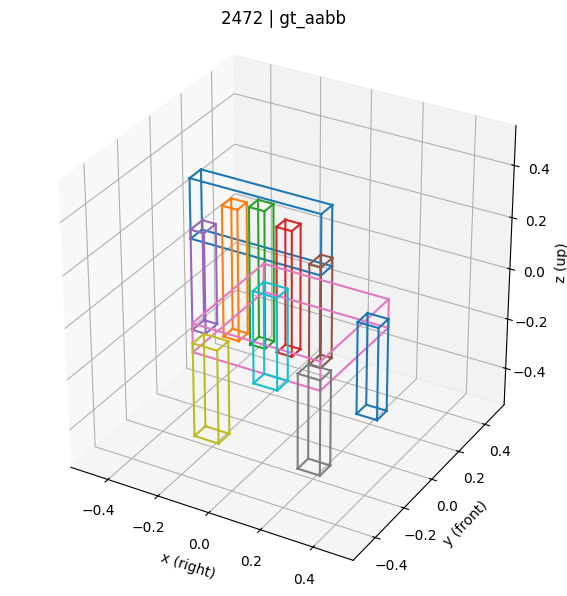

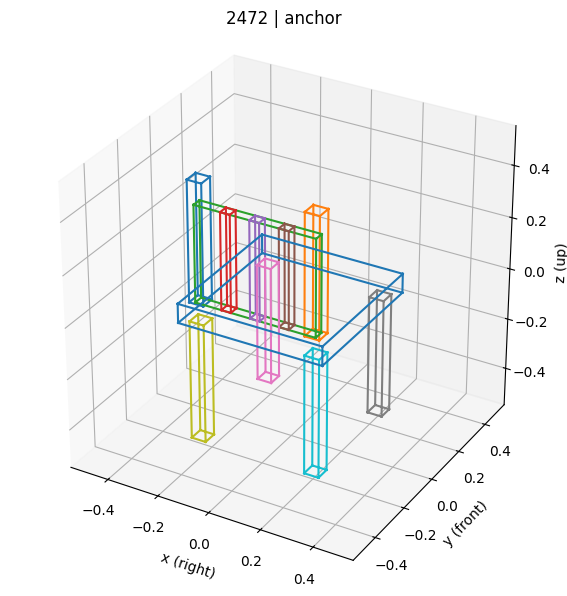

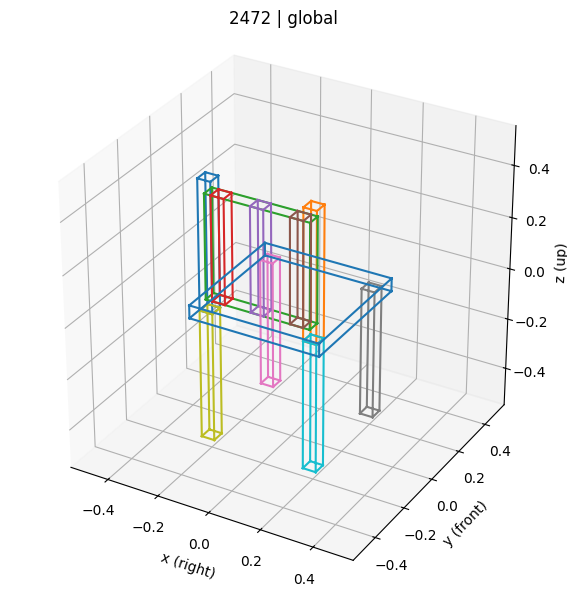

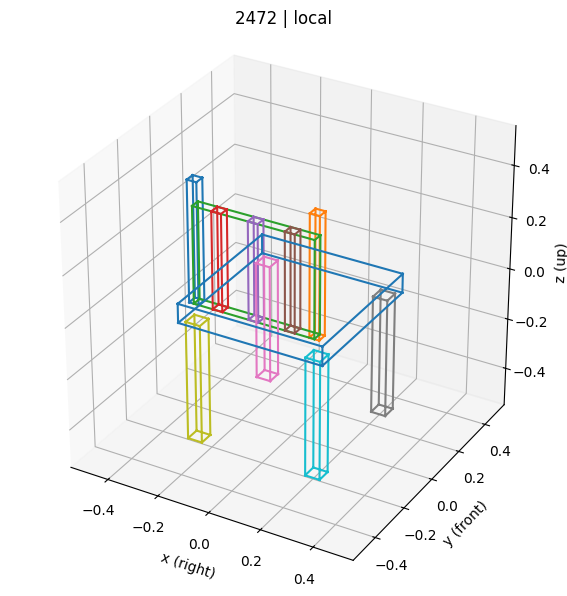

In [95]:
visual_object_id = evaluation["complete_ids"][0] if evaluation["complete_ids"] else None
if visual_object_id is not None:
    figure_paths = visualize_partnet_comparison(visual_object_id, evaluation, gt_cache, cfg)
else:
    print("尚无三方法共同有效对象；查看 tables/generation_status.csv。")

## 文件输出与复现说明

`partnet_results/` 下保存：

| 路径 | 内容 |
|---|---|
| `run_manifest.json` | 冻结输入 hash、对象 ID、统一 generation 配置 |
| `shared/{id}.json` | 共享 connections 的原始回复/历史导入、校验结果、累计 attempts |
| `generation/{anchor,global,local}/{id}.json` | 每个分支的原始回复、模型返回名、usage、prompt、解析结果 |
| `gt/{id}.json` | normalized GT geometry 与已有 adjacency |
| `evaluation/{method}/{id}.json` | matching、normalized layout、object-level metrics |
| `random_anchor/{id}.json` | 每个 seed 的结果及 object-level average |
| `perturbation/{method}/{id}.json` | 每条 edge 的单独 intervention 和 object-level 汇总 |
| `tables/summary.csv` | complete-case 主表；另有 category、all-available、statistics 和 status 表 |
| `evaluation_protocol.json` | 指标公式语义、匹配/归一化/统计口径和未实现范围 |
| `figures/` | 定性 bbox 布局 |


In [96]:
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
result_dir=Path(cfg.output_path())
required_files=["tables/results.json","evaluation_protocol.json","run_manifest.json","llm_runtime_metadata.json"]
missing_files=[name for name in required_files if not (result_dir/name).is_file()]
if missing_files:
    raise FileNotFoundError(f"缺少结果文件：{missing_files}。请确认 Cell 10 已成功导出，或检查 result_dir。")
review_zip=result_dir.parent/"partnet_results_review.zip"
with ZipFile(review_zip,"w",compression=ZIP_DEFLATED) as archive:
    for name in required_files:
        archive.write(result_dir/name,arcname=f"partnet_results/{name}")
    figure_dir=result_dir/"figures"
    if figure_dir.is_dir():
        for path in sorted(figure_dir.glob("*.png")):
            archive.write(path,arcname=f"partnet_results/figures/{path.name}")
print("结果包：",review_zip.resolve())
print("大小 MB：",round(review_zip.stat().st_size/1024**2,2))

结果包： D:\MyJupyter\Works\ASPT\partnet_results_review.zip
大小 MB： 0.97


In [99]:
import importlib
import methods
import pandas as pd
from IPython.display import display
importlib.reload(methods)
from methods import *
cfg.allow_api = False
cfg.scale_factors = (0.8, 1.2, 1.5)
cfg.bootstrap_samples = 10000

In [100]:
same_geometry = run_partnet_same_geometry_control(cfg)
summary_frame = pd.DataFrame(same_geometry["summary"])
display(summary_frame.pivot(index=["scale", "method"], columns="metric", values="mean").round(6))
stat_columns = ["scale", "baseline", "n", "anchor_mean", "baseline_mean", "mean_improvement", "ci_low", "ci_high", "holm_p", "wins", "ties", "losses"]
display(pd.DataFrame(same_geometry["paired_statistics"])[stat_columns])
print("objects:", same_geometry["object_count"])
print("max initial reconstruction error:", max(row["max_roundtrip_error"] for row in same_geometry["checks"]))
print("max Global-Local margin difference:", max(row["global_local_margin_max_difference"] for row in same_geometry["checks"]))

Same-geometry control: 20/877
Same-geometry control: 40/877
Same-geometry control: 60/877
Same-geometry control: 80/877
Same-geometry control: 100/877
Same-geometry control: 120/877
Same-geometry control: 140/877
Same-geometry control: 160/877
Same-geometry control: 180/877
Same-geometry control: 200/877
Same-geometry control: 220/877
Same-geometry control: 240/877
Same-geometry control: 260/877
Same-geometry control: 280/877
Same-geometry control: 300/877
Same-geometry control: 320/877
Same-geometry control: 340/877
Same-geometry control: 360/877
Same-geometry control: 380/877
Same-geometry control: 400/877
Same-geometry control: 420/877
Same-geometry control: 440/877
Same-geometry control: 460/877
Same-geometry control: 480/877
Same-geometry control: 500/877
Same-geometry control: 520/877
Same-geometry control: 540/877
Same-geometry control: 560/877
Same-geometry control: 580/877
Same-geometry control: 600/877
Same-geometry control: 620/877
Same-geometry control: 640/877
Same-geometr

metric        baseline_contact_deviation  contact_deviation  deviation_change  \
scale method                                                                    
0.8   anchor                    0.027839           0.024964         -0.002875   
      global                    0.027839           0.042438          0.014599   
      local                     0.027839           0.042438          0.014599   
1.2   anchor                    0.027839           0.030502          0.002662   
      global                    0.027839           0.046592          0.018752   
      local                     0.027839           0.046592          0.018752   
1.5   anchor                    0.027839           0.034261          0.006421   
      global                    0.027839           0.069885          0.042046   
      local                     0.027839           0.069885          0.042046   

metric        margin_drift  
scale method                
0.8   anchor      0.002875  
      global      0.021981  
      local       0.021981  
1.2   anchor      0.002663  
      global      0.018821  
      local       0.018821  
1.5   anchor      0.006422  
      global      0.042218  
      local       0.042218

,scale,baseline,n,anchor_mean,baseline_mean,mean_improvement,ci_low,ci_high,holm_p,wins,ties,losses
0,0.8,global,877,0.002875,0.021981,0.019105,0.018348,0.019865,1.205749e-128,841,3,33
1,0.8,local,877,0.002875,0.021981,0.019105,0.018348,0.019865,1.205749e-128,841,3,33
2,1.2,global,877,0.002663,0.018821,0.016159,0.015481,0.016846,9.219416e-124,839,4,34
3,1.2,local,877,0.002663,0.018821,0.016159,0.015481,0.016846,9.219416e-124,839,4,34
4,1.5,global,877,0.006422,0.042218,0.035796,0.034118,0.037478,1.095071e-121,840,4,33
5,1.5,local,877,0.006422,0.042218,0.035796,0.034118,0.037478,1.095071e-121,840,4,33


objects: 877
max initial reconstruction error: 6.661338147750939e-16
max Global-Local margin difference: 1.1102230246251565e-16


In [101]:
corrected_results = refresh_partnet_statistics_from_cache(cfg)

统计已更新：39 tests；原始 tables/results.json 未覆盖。


In [102]:
from zipfile import ZipFile, ZIP_DEFLATED
review_files = ["same_geometry/results.json", "tables/results_tie_corrected.json"]
review_path = cfg.output_path("stage2_completion_review.zip")
with ZipFile(review_path, "w", compression=ZIP_DEFLATED) as archive:
    for name in review_files:
        path = cfg.output_path(name)
        if not path.is_file():
            raise FileNotFoundError(path)
        archive.write(path, arcname=name)
print("上传这个结果包：", review_path.resolve())

上传这个结果包： D:\MyJupyter\Works\ASPT\partnet_results\stage2_completion_review.zip
